# CNN Detector — Development Log

**What this is.** The story of the deep-learning detector: what we tried, what we found, and what
we ruled out. Written so that in six months it explains not just *what the numbers were* but *why
each experiment was shaped the way it was* — including the readings we got wrong and retracted.

**How to read it.** Chronological, one section per experiment, each with the same five headings:
the question · the setup · the results · what it showed · what it changed.

**How to extend it.** Add a new section in the same format at the end of the experiment list, using
the template in `scripts/build_cnn_log_notebook.py`, then re-run that script. Results are computed
from saved artefacts in `results/`, not pasted in, so re-running refreshes them.

**Scope.** This file covers the *network*. Milestone-numbered background — the radar re-spec, the
CFAR window selection, the data-quality audit, the clutter-edge investigation — lives in
`PROGRESS.md` and is cross-referenced rather than repeated.

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

DL = ROOT / "results" / "dl"

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#898781", "#e1e0d9"
TRAIN, VAL, DLC, CFARC = "#2a78d6", "#eb6834", "#2a78d6", "#898781"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID,
                     "axes.grid": True, "grid.alpha": 0.6, "figure.dpi": 120})

def history(tag):
    p = DL / f"history_{tag}.json"
    return pd.DataFrame(json.load(open(p))) if p.exists() else None

# Cumulative archive of every checkpoint ever scored (see scripts/compare_checkpoints.py).
HIST = pd.read_csv(DL / "checkpoint_history.csv") if (DL / "checkpoint_history.csv").exists() else None

# CFAR on the SAME split, for every comparison below.
CFAR_VAL = pd.read_csv(ROOT / "results" / "cfar_val" / "summary.csv")
CFAR_BEST = (CFAR_VAL.dropna(subset=["pd"]).loc[CFAR_VAL.dropna(subset=["pd"])
             .groupby("condition").pd.idxmax()][["condition", "method", "pd"]]
             .set_index("condition"))
print("CFAR best per condition on bench2_val:")
print(CFAR_BEST.round(3).to_string())

CFAR best per condition on bench2_val:
             method     pd
condition                 
clutter          GO  0.149
clutter_edge     OS  0.443
isolated         CA  0.710
masking          OS  0.645
mixed            GO  0.426
multi            CA  0.680
unresolved       CA  0.485


---
## Standing decisions, and why

These constrain every experiment below. They were each forced by a specific finding, so the reason
is recorded with the rule.

**1 — `bench2_val` for every comparison while choices are still open. `bench2_test` stays
untouched.** The test split was measured once for the pre-registered CFAR baseline (`PROGRESS.md`
Milestone 21) and is not read again until the configuration is locked. The cost is a wider noise
floor — 200 frames per condition against test's 400 — and that is the right price for keeping the
reported numbers uncontaminated by the choices we are still making.

**2 — Validation loss is not a stopping signal here.** It plateaued from ~epoch 26 while Pd on the
clutter-bearing conditions *appeared* to still be moving. Loss is a proxy; the reported metric is Pd
at matched measured Pfa, and when the two disagreed we followed Pd. (The apparent movement later
turned out to be seed noise — see Corrections — but the principle stands: the proxy and the metric
disagreed, so the proxy lost.)

**3 — Single-seed results are not trusted.** The noise floor must be known before any comparison is
believed. One trajectory cannot separate "the model changed" from "the evaluation is noisy"; only
varying the seed can.

**4 — Loss values are not comparable across `pos_weight` values.** The loss scale is set by
`pos_weight × positive_rate`. Only Pd at matched measured Pfa is comparable across configurations.

**5 — Operating point is always matched *measured* Pfa**, swept per condition, never design Pfa.
Rationale in `PROGRESS.md` step 5: clutter drives achieved rates 60–125× above design, by different
factors per method.

---
## 1 · Initial runs — 12 epochs (old sensor) and 50 epochs (current)

### Question
Does the pipeline work end to end, and where does training stop improving?

### Setup
| | 12-epoch run | 50-epoch run |
|---|---|---|
| when | 2026-07-31 | 2026-08-11 |
| sensor | old 256×128 | current 256×64 (CARRADA-matched) |
| data | `bench_train` 9,600 | `bench2_train` **8,400 (all)** |
| val | 800 of 1,600 | **1,600 (all)** |
| epochs | 12, fixed | 50, no early stopping |
| `pos_weight` | 200 | 974 |
| command | notebook, since deleted (`14b38bd`) | `python scripts/train_tinycnn.py --epochs 50 --tag bench` |

The 12-epoch run's numbers do not carry over — different sensor, different class ratio, and it had
three defects fixed since: it stopped at a fixed epoch count with val loss *still falling*, kept the
last epoch rather than the best, and used half the validation set.

The 50-epoch run also rebuilt the infrastructure: a script instead of a notebook (a run is now a
command with a recorded config), a pre-normalised cache (reading 8,400 `.npy` files cost 325 s/epoch
against 89 s of compute), and seeded determinism — later **verified** when a 30-epoch re-run
reproduced epochs 27–30 of the original to all five decimals.

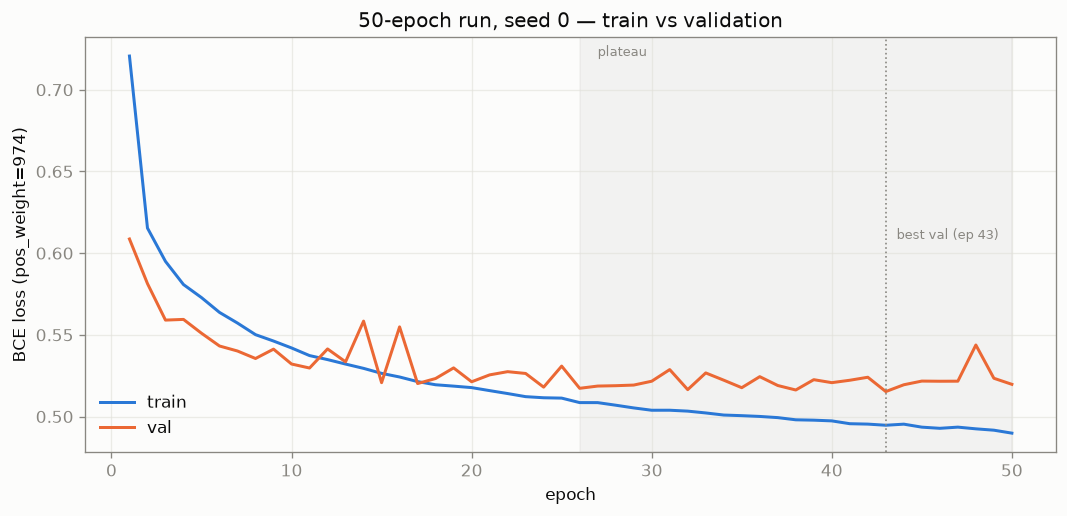

best val 0.51529 at epoch 43;  last 0.51971 at 50
train 0.72061 -> 0.48984


In [2]:
h = history("bench")
if h is not None:
    fig, ax = plt.subplots(figsize=(9, 4.4))
    ax.plot(h.epoch, h.train_loss, color=TRAIN, lw=1.8, label="train")
    ax.plot(h.epoch, h.val_loss, color=VAL, lw=1.8, label="val")
    b = int(h.val_loss.idxmin()) + 1
    ax.axvline(b, color=MUTED, ls=":", lw=1)
    ax.text(b + 0.6, h.val_loss.max(), f"best val (ep {b})", fontsize=8, color=MUTED)
    ax.axvspan(26, 50, color=MUTED, alpha=0.08)
    ax.text(27, h.train_loss.max(), "plateau", fontsize=8, color=MUTED)
    ax.set_xlabel("epoch"); ax.set_ylabel(f"BCE loss (pos_weight=974)")
    ax.set_title("50-epoch run, seed 0 — train vs validation")
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

    print(f"best val {h.val_loss.min():.5f} at epoch {b};  last {h.val_loss.iloc[-1]:.5f} at 50")
    print(f"train {h.train_loss.iloc[0]:.5f} -> {h.train_loss.iloc[-1]:.5f}")

### What it showed
Gates all passed: receptive field measured **21×9** (matching the CFAR window, which is what makes
this a controlled experiment — see `PROGRESS.md` Milestone 13), overfit-one-batch collapsed 1370×
with 17/17 peaks within 1 bin, cache byte-identical to reading frames individually.

Best val 0.51529 at epoch 43, last 0.51971 at 50. Train kept falling throughout.

### What it changed
Nothing yet — the stopping question moved to the trend analysis below.

---
## 2 · Trend analysis on validation loss

### Question
Is validation loss still improving after ~epoch 26, or has it plateaued? Should we run to 100?

### Setup
Linear trend fits on the 50-epoch history above, seed 0. No new compute.

In [3]:
h = history("bench")
rows = []
for lo in (20, 26, 35):
    m = h.epoch >= lo
    s = stats.linregress(h.epoch[m], h.val_loss[m])
    rows.append(dict(window=f"{lo}-50", slope=s.slope, p=s.pvalue,
                     ci_lo=s.slope - 1.96 * s.stderr, ci_hi=s.slope + 1.96 * s.stderr))
st = stats.linregress(h.epoch[h.epoch >= 26], h.train_loss[h.epoch >= 26])
rows.append(dict(window="train 26-50", slope=st.slope, p=st.pvalue,
                 ci_lo=st.slope - 1.96 * st.stderr, ci_hi=st.slope + 1.96 * st.stderr))
display(pd.DataFrame(rows).set_index("window").round(6))

noise = h.val_loss.tail(25).std()
proj = stats.linregress(h.epoch[h.epoch >= 26], h.val_loss[h.epoch >= 26]).slope * 50
print(f"epoch-to-epoch val noise (std, last 25): {noise:.4f}")
print(f"projected val change over 50 MORE epochs: {proj:+.4f}  ({abs(proj)/noise:.1f}x the noise)")
print(f"train-val gap: {h.val_loss[25]-h.train_loss[25]:+.4f} @26 -> "
      f"{h.val_loss[49]-h.train_loss[49]:+.4f} @50")

,slope,p,ci_lo,ci_hi
window,,,,
20-50,0.000022,0.845595,-0.000198,0.000242
26-50,0.000216,0.169310,-0.000082,0.000514
35-50,0.000471,0.180282,-0.000184,0.001126
train 26-50,-0.000731,0.000000,-0.000772,-0.000691


epoch-to-epoch val noise (std, last 25): 0.0056
projected val change over 50 MORE epochs: +0.0108  (1.9x the noise)
train-val gap: +0.0087 @26 -> +0.0299 @50


### What it showed
Validation loss is **statistically flat**: slope +0.0002/epoch over epochs 26–50 with **p = 0.17**,
and p = 0.85 over 20–50. Training loss over the same span falls at −0.0007/epoch with **p = 1.3e-21**
— unmistakably real. The train–val gap widens from +0.009 to +0.030: mild overfitting, no upward
turn in val.

Projecting the val trend over another 50 epochs predicts a change of 0.011 against a 0.0055
epoch-to-epoch noise floor — about two noise widths. With 5,041 parameters against 8,400 frames, the
classic U-shaped validation curve should not be expected at all; flat-forever is the likely shape.

### What it changed
**Cancelled a proposed 100-epoch run** — it would have cost 90 minutes to observe a signal the same
size as the noise. And it demoted loss as the deciding quantity: the stopping question moved to Pd.

> ⚠️ At this point we drew a *further* conclusion that was wrong — that the plateau meant training
> was effectively done. See Corrections.

---
## 3 · Measured class ratio, and `pos_weight` 200 → 974

### Question
Is `pos_weight=200` justified by the actual class balance?

### Setup
Exact count over **every cell** of the cached labels for both splits — not sampled.

In [4]:
from dl.dataset import cache_paths
rows = []
for split in ("bench2_train", "bench2_val"):
    y = np.load(cache_paths(split)[1], mmap_mode="r")
    pos = tot = 0
    for i in range(0, len(y), 500):
        blk = np.asarray(y[i:i + 500]); pos += int(blk.sum()); tot += blk.size
    rows.append(dict(split=split, positive=pos, total=tot, rate=pos / tot, ratio=f"1:{tot/pos:.0f}"))
display(pd.DataFrame(rows).set_index("split"))

print("loss scale is set by pos_weight x positive_rate:")
print(f"   old sensor: 200 / 1563 = {200/1563:.3f}")
print(f"   now:        974 /  974 = {974/974:.3f}   -> {(974/974)/(200/1563):.1f}x larger")
print("\nVerified directly: the SAME trained model on the SAME val set scores")
print("   0.27555 at pos_weight=200   and   0.51529 at pos_weight=974")

,positive,total,rate,ratio
split,,,,
bench2_train,144996,137625600,0.001054,1:949
bench2_val,26943,26214400,0.001028,1:973


loss scale is set by pos_weight x positive_rate:
   old sensor: 200 / 1563 = 0.128
   now:        974 /  974 = 1.000   -> 7.8x larger

Verified directly: the SAME trained model on the SAME val set scores
   0.27555 at pos_weight=200   and   0.51529 at pos_weight=974


### What it showed
The imbalance is real — 144,996 positive cells in 137.6 million, per-frame counts landing on exact
multiples of 9 (the 3×3 label blob per target).

**`pos_weight=200` was never justified by anything.** On the old sensor the ratio was 1:1563, so 200
sat ~8× below the inverse frequency; it then survived a sensor change that moved the ratio to
~1:950. A guess that outlived its premise.

### What it changed
Set `pos_weight` to the measured inverse frequency, **974** — recording that this is *also* an
assumption, since exact class balancing is a choice rather than a derivation. An ablation over
{100, 200, 974} is queued (see Open).

It also made **standing decision 4** necessary: the loss scale moved 7.8×, so no loss value is
comparable across runs with different `pos_weight`.

---
## 4 · Checkpoints 30 / 43 / 50, single seed

### Question
Do checkpoints from across the loss plateau differ in the metric we actually report? If they
coincide, the stopping-epoch question is closed; if they scatter, the evaluation is noisier than the
loss curve suggests.

### Setup
`python scripts/compare_checkpoints.py --checkpoints ep030 best last` · seed 0 only ·
`bench2_val`, 1,600 frames · per-condition threshold sweep to matched measured Pfa 1e-4.

Epoch 30 was recovered by re-running 30 epochs at the same seed — deterministic, and its epochs
27–30 matched the original exactly. `--save-every` / `--save-at` were added so this cannot recur.

In [5]:
single = HIST[HIST.checkpoint.isin(["tinycnn_ep30_ep030", "tinycnn_bench_best",
                                    "tinycnn_bench_last"])] if HIST is not None else None
if single is not None and len(single):
    piv = single.pivot_table(index="condition", columns="epoch", values="pd").dropna()
    piv["spread"] = piv.max(axis=1) - piv.min(axis=1)
    display(piv.round(3).sort_values("spread"))
else:
    print("run: python scripts/compare_checkpoints.py --checkpoints ep030 best last")

epoch,30,43,50,spread
condition,,,,
unresolved,0.488,0.488,0.488,0.000
masking,0.705,0.702,0.702,0.002
multi,0.708,0.718,0.715,0.010
isolated,0.720,0.730,0.725,0.010
clutter,0.132,0.112,0.127,0.020
mixed,0.489,0.497,0.515,0.025
clutter_edge,0.664,0.705,0.711,0.047


### What it showed — ambiguous, and split by condition
Clean and interference conditions were settled (spread 0.000–0.010): `unresolved` 0.488 flat,
`masking` 0.702–0.705, `isolated` and `multi` within 0.010. For those the stopping epoch does not
matter.

Clutter-bearing conditions were not, and two moved **monotonically upward**: `clutter_edge`
0.664 → 0.705 → 0.711 and `mixed` 0.489 → 0.497 → 0.515.

**The flaw, stated at the time:** these three checkpoints are the *same training trajectory*, so
their spread confounds genuine model change with evaluation noise and cannot separate them. Three
correlated points cannot establish a trend.

### What it changed
Deferred the `pos_weight` ablation until the noise floor was known, and made a like-for-like CFAR
run on `bench2_val` necessary — the CFAR baseline was on `bench2_test` and the two cannot be read
across.

> ⚠️ We nonetheless read the monotone climb as real improvement. It was not. See Corrections.

---
## 5 · CFAR on `bench2_val` — how much of the clutter gap was a split artefact?

### Question
The DL numbers are on `bench2_val`; the CFAR baseline is on `bench2_test`. Does the apparent DL
clutter deficit survive on the *same* split?

### Setup
`python scripts/cfar_test_baseline.py --split bench2_val` · same protocol as the DL evaluation:
21×9 window, per-condition sweep to matched measured Pfa 1e-4 · `bench2_test` untouched.

In [6]:
cmp = CFAR_VAL.pivot_table(index="condition", columns="method", values="pd")[["CA", "GO", "OS"]]
cmp["best CFAR"] = cmp.max(axis=1)
cmp["best method"] = cmp[["CA", "GO", "OS"]].idxmax(axis=1)
display(cmp.round(3))

test = pd.read_csv(ROOT / "results" / "cfar_test" / "summary.csv")
side = pd.DataFrame({
    "CFAR val": CFAR_VAL.pivot_table(index="condition", columns="method", values="pd").max(axis=1),
    "CFAR test": test.pivot_table(index="condition", columns="method", values="pd").max(axis=1),
}).dropna()
side["val - test"] = side["CFAR val"] - side["CFAR test"]
print("\nCFAR scores differently on the two splits — which is why cross-split reads mislead:")
display(side.round(3))

method,CA,GO,OS,best CFAR,best method
condition,,,,,
clutter,0.134,0.149,0.137,0.149,GO
clutter_edge,0.419,0.426,0.443,0.443,OS
isolated,0.710,0.700,0.710,0.710,CA
masking,0.515,0.522,0.645,0.645,OS
mixed,0.400,0.426,0.373,0.426,GO
multi,0.680,0.671,0.676,0.680,CA
unresolved,0.485,0.482,0.485,0.485,CA



CFAR scores differently on the two splits — which is why cross-split reads mislead:


,CFAR val,CFAR test,val - test
condition,,,
clutter,0.149,0.171,-0.022
clutter_edge,0.443,0.449,-0.006
isolated,0.710,0.675,0.035
masking,0.645,0.622,0.022
mixed,0.426,0.426,-0.000
multi,0.680,0.687,-0.007
unresolved,0.485,0.464,0.021


### What it showed
CFAR scores **0.149** on `clutter` on val against **0.171** on test. So the earlier "DL 0.127 vs
CFAR 0.171" was comparing two different splits and **overstated the gap roughly twofold**. On the
same split the deficit is 0.127 vs 0.149 — about 0.022, and at that point the same size as the
0.020 drift already seen across epochs on that condition.

### What it changed
Established the like-for-like baseline every later comparison uses. Also flagged `clutter_edge`
(+0.268 over the best classical method) as needing attribution before being reported — see Open.

---
## 6 · The noise floor — 3 seeds, epochs 15 and 30

### Question
(a) What is the seed-to-seed spread at a fixed epoch — our noise floor? (b) Does `clutter_edge` keep
climbing past epoch 50?

### Setup
3 seeds × 100 epochs planned, `pos_weight=974`, checkpoints at 15/30/50/75/100.
**The laptop slept at epoch 31 and all three died** — epochs 15 and 30 survived.

The run could not be resumed because only model weights were being checkpointed; optimizer moments
and RNG state were not. Training now writes a full resume state every 5 epochs, atomically renamed,
and `--keep-awake` asks the OS not to sleep for the duration.

In [7]:
ns = HIST[HIST.checkpoint.str.match(r"tinycnn_s[012]_ep0(15|30)")] if HIST is not None else None
if ns is not None and len(ns):
    for ep in sorted(ns.epoch.unique()):
        sub = ns[ns.epoch == ep].pivot_table(index="condition", columns="seed", values="pd").dropna()
        sub["spread"] = sub.max(axis=1) - sub.min(axis=1)
        print(f"EPOCH {ep} — Pd by seed (spread = the noise floor)")
        display(sub.round(3))
    ep15 = ns[ns.epoch == 15].groupby("condition").pd.mean()
    ep30 = ns[ns.epoch == 30].groupby("condition").pd.mean()
    chg = (ep30 - ep15).rename("epoch 15->30 change").to_frame()
    chg["seed spread @30"] = (ns[ns.epoch == 30].groupby("condition").pd.max()
                              - ns[ns.epoch == 30].groupby("condition").pd.min())
    chg["noise / signal"] = chg["seed spread @30"] / chg["epoch 15->30 change"].abs()
    display(chg.round(3).sort_values("seed spread @30", ascending=False))
else:
    print("run: python scripts/compare_checkpoints.py --checkpoints 's*_ep015' 's*_ep030'")

EPOCH 15 — Pd by seed (spread = the noise floor)


seed,0,1,2,spread
condition,,,,
clutter,0.109,0.132,0.124,0.022
clutter_edge,0.681,0.681,0.668,0.013
isolated,0.715,0.735,0.725,0.020
masking,0.698,0.702,0.698,0.005
mixed,0.499,0.478,0.484,0.021
multi,0.707,0.699,0.706,0.008
unresolved,0.488,0.490,0.490,0.003


EPOCH 30 — Pd by seed (spread = the noise floor)


seed,0,1,2,spread
condition,,,,
clutter,0.137,0.124,0.119,0.017
clutter_edge,0.664,0.664,0.718,0.054
isolated,0.730,0.740,0.720,0.020
masking,0.700,0.700,0.705,0.005
mixed,0.493,0.485,0.513,0.027
multi,0.713,0.719,0.710,0.009
unresolved,0.488,0.490,0.488,0.003


,epoch 15->30 change,seed spread @30,noise / signal
condition,,,
clutter_edge,0.006,0.054,9.600
mixed,0.010,0.027,2.625
isolated,0.005,0.020,4.000
clutter,0.005,0.017,3.500
multi,0.010,0.009,0.889
masking,0.002,0.005,2.000
unresolved,-0.001,0.003,3.000
noise,NaN,NaN,NaN


### What it showed — the result that reshaped the plan
**The noise floor is larger than the effect.** Changing the seed moved `clutter_edge` by up to
**0.054** at one fixed epoch. Training from epoch 15 to 30 moved it by **0.006** — nine times
smaller. At epoch 30, seeds 0 and 1 both gave 0.664 while seed 2 gave 0.718.

### What it changed
1. **Killed the 100-epoch plan.** Question (b) presumes a climb the data does not support; another
   six hours would have produced another number inside the same ±0.054 band.
2. **Closed the stopping-epoch question.** Nothing moves more than 0.010 between epochs 15 and 30,
   well under the noise, so anything from ~15 onward is equivalent.
3. **Buy seeds, not epochs** — the missing quantity was an error bar, not a longer curve.
4. Set the bar for the `pos_weight` ablation: single-seed it would have to beat 0.054 to mean
   anything.

---
## 7 · 8 seeds × 50 epochs — the headline comparison

### Question
What are the per-condition mean ± standard error, and does the DL clutter deficit against CFAR
survive once error bars are attached?

### Setup
```
for S in 0..7: python scripts/train_tinycnn.py --epochs 50 --seed $S --tag n$S \
    --pos-weight 974 --save-at 15,30,50 --threads 2 --resume --keep-awake --skip-gates
```
Identical to the 50-epoch baseline except the seed. `pos_weight=974` **fixed**, not re-measured per
run, so it cannot drift between seeds. All 8,400 train / 1,600 val frames. ~525 s/epoch, 8 processes
at 2 threads. Evaluated at epoch 50 on `bench2_val`, per-condition sweep to matched measured
Pfa 1e-4.

In [8]:
d50 = HIST[(HIST.epoch == 50) & HIST.checkpoint.str.startswith("tinycnn_n")] if HIST is not None else None
d50 = d50[d50.pd.notna()]

rows = []
for c, g in d50.groupby("condition"):
    if c not in CFAR_BEST.index:
        continue
    v = g.pd.values
    m, sd = v.mean(), v.std(ddof=1)
    se = sd / np.sqrt(len(v))
    cf = float(CFAR_BEST.loc[c, "pd"])
    t, p = stats.ttest_1samp(v, cf)
    rows.append(dict(condition=c, n=len(v), DL_mean=m, std=sd, SE=se,
                     ci_lo=m - 1.96 * se, ci_hi=m + 1.96 * se,
                     CFAR=cf, best=CFAR_BEST.loc[c, "method"], delta=m - cf, p=p))
res = pd.DataFrame(rows).set_index("condition").sort_values("delta")
display(res.round(4))

,n,DL_mean,std,SE,ci_lo,ci_hi,CFAR,best,delta,p
condition,,,,,,,,,,
clutter,8,0.1247,0.0092,0.0032,0.1183,0.1310,0.1493,GO,-0.0246,0.0001
unresolved,8,0.4869,0.0022,0.0008,0.4853,0.4884,0.4850,CA,0.0019,0.0479
isolated,8,0.7319,0.0037,0.0013,0.7293,0.7345,0.7100,CA,0.0219,0.0000
multi,8,0.7113,0.0059,0.0021,0.7072,0.7154,0.6804,CA,0.0309,0.0000
masking,8,0.6941,0.0108,0.0038,0.6866,0.7015,0.6450,OS,0.0491,0.0000
mixed,8,0.5121,0.0059,0.0021,0.5080,0.5162,0.4255,GO,0.0866,0.0000
clutter_edge,8,0.7043,0.0114,0.0040,0.6964,0.7122,0.4430,OS,0.2613,0.0000


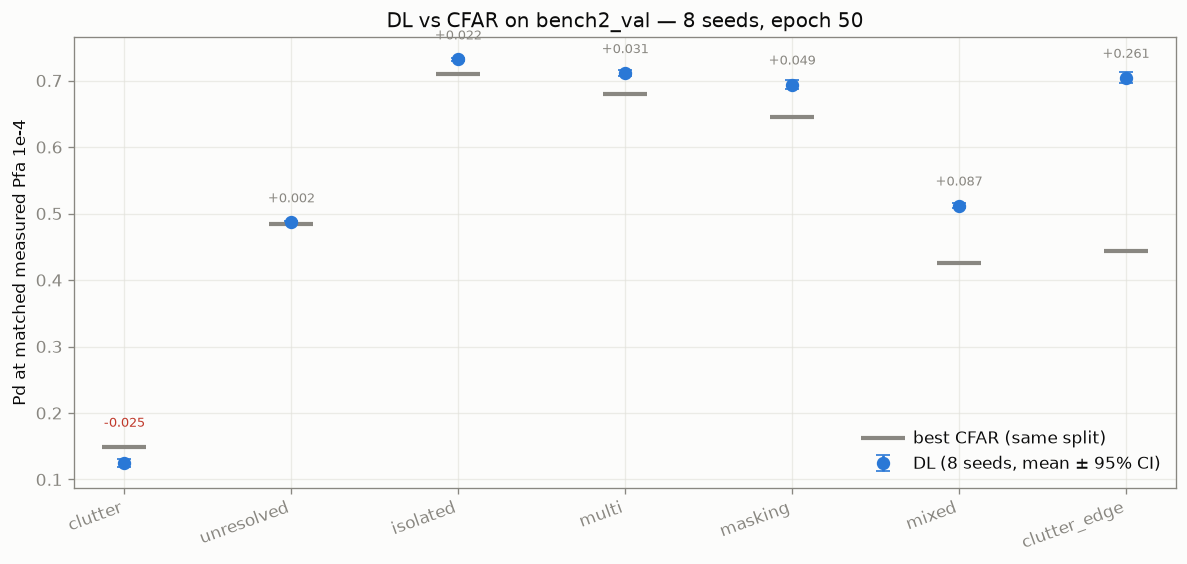

per-seed Pd on `clutter` (every seed below CFAR's 0.149):
[0.109 0.119 0.122 0.122 0.124 0.127 0.134 0.139]


In [9]:
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(res))
ax.errorbar(x, res.DL_mean, yerr=1.96 * res.SE, fmt="o", color=DLC, capsize=4, ms=7,
            lw=1.6, label="DL (8 seeds, mean ± 95% CI)")
ax.plot(x, res.CFAR, "_", color=CFARC, ms=26, mew=2.5, label="best CFAR (same split)")
for i, (c, r) in enumerate(res.iterrows()):
    ax.annotate(f"{r.delta:+.3f}", (i, max(r.DL_mean, r.CFAR) + 0.03),
                ha="center", fontsize=8,
                color="#c0392b" if r.delta < 0 else MUTED)
ax.set_xticks(x); ax.set_xticklabels(res.index, rotation=20, ha="right")
ax.set_ylabel("Pd at matched measured Pfa 1e-4")
ax.set_title("DL vs CFAR on bench2_val — 8 seeds, epoch 50")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

print("per-seed Pd on `clutter` (every seed below CFAR's 0.149):")
print(np.round(np.sort(d50[d50.condition == "clutter"].pd.values), 3))

### What it showed
**The clutter deficit survives, decisively.** DL 0.125 ± 0.0032, 95% CI [0.118, 0.131]; CFAR's GO
sits at 0.149, well outside it, p = 0.00014. **All eight seeds land below GO** (0.109–0.139). CFAR
genuinely beats the network on targets inside the clutter ridge.

That matters beyond the number. `PROGRESS.md` Milestone 17 noted that a credible learned detector
normally loses *somewhere*, and that ours previously lost nowhere. It now loses somewhere, on a
condition with a physical explanation.

Everywhere else DL wins with p < 1e-5: `mixed` +0.086, `masking` +0.049, `multi` +0.031,
`isolated` +0.022.

**Seed variance shrinks as training converges.** SE on `clutter_edge` at epoch 50 is **0.0040**
(std 0.0114, range 0.033 over 8 seeds) against the 0.054 spread measured over 3 seeds at epoch 30.
Since range normally *grows* with sample size, that is not sampling luck — the seeds genuinely
converge. So the epoch-30 noise floor overstated the floor at epoch 50.

### What it changed
Gives the first DL-vs-CFAR statement with uncertainty attached, and identifies `clutter` as the
network's genuine weakness — the anchor for the attribution work in `PROGRESS.md` Milestone 18.

---
## Corrections

Claims made and later retracted, with the evidence in each case. Kept because the reasoning error
matters more than the number.

### C1 — "`clutter_edge` is still climbing past the loss plateau"
**Claimed** (§4): the monotone rise 0.664 → 0.705 → 0.711 across epochs 30/43/50 was *"the shape of
continued improvement, not scatter"*, and that stopping at epoch 26 would have cost ~0.04 Pd.

**Retracted by** §6. The three points came from one trajectory, and seed-to-seed spread at a *fixed*
epoch is 0.054 — nine times the 0.006 that training from 15 to 30 actually produces. At epoch 30,
seeds 0 and 1 both give 0.664 while seed 2 gives 0.718. The 50-epoch run was seed 0, so its 0.711 is
as well explained by *which seed it was* as by *how long it trained*.

**The reasoning error:** §4 explicitly flagged that three correlated points could not separate model
change from evaluation noise — and then read a trend into them anyway. A stated caveat is not a
substitute for the experiment that resolves it.

### C2 — "8 seeds will give SE ≈ 0.011 on `clutter_edge`"
**Claimed** when proposing the 8-seed run, extrapolating from the 3-seed epoch-30 spread of 0.054.

**Actual:** SE **0.0040** at epoch 50 — nearly 3× tighter.

**Why:** the estimate assumed seed variance is constant across training. It is not; it shrinks as
the run converges (§7). A 3-seed spread is also a poor variance estimator in its own right. The
prediction was conservative in the useful direction — the experiment was better powered than
promised — but it was wrong about the mechanism.

---
## Open / not yet reported

Findings that exist but should **not** go in the report in their current state.

### O1 — `clutter_edge` +0.261: ATTRIBUTED (2026-08-13), and it survives

**Question.** Is the margin an edge effect, or an artefact of the stratum's 34% dilution
(`PROGRESS.md` Milestone 22)?

**Check 1 — against OS specifically, not just "best classical".** OS-CFAR is the method designed for
edge contamination, so if the margin shrank against it the finding would be narrower than it looks.
It does not: **OS *is* the best classical method on this condition** (0.443, against CA 0.419 and
GO 0.426), so +0.261 was always measured against OS. The margin against CA is +0.285 and against GO
+0.278 — OS's edge design buys it only 0.017–0.024 over its siblings. This echoes Milestone 22: at
matched *measured* Pfa, an edge-robust design shows up as fewer false alarms, not higher Pd, and
matching the rate cancels precisely that.

**Check 2 — where the margin falls relative to the clutter boundary.** Split by **target clearance
from the ridge edge in Doppler bins** — fixed by the data, so no window or detector can shift it.
The ridge spans ±4 bins; the 21×9 training ring sits at offsets ±3–4 from the target, so clearance
2–4 means the ring genuinely overlaps the ridge and clearance ≥5 means it never does (**28%** of
frames on val, consistent with Milestone 22's 24.5% frame-level figure on test).

The two hypotheses predict different shapes: **H-window** (reference-window contamination) says the
margin concentrates where the ring is contaminated; **H-dilution** says it is uniform, i.e. not an
edge effect at all.

`python scripts/attribute_clutter_edge.py` · `bench2_val` · CFAR from cached peaks, DL averaged over
all 8 seeds · matched measured Pfa 1e-4 swept **within each band**.

,n frames,true edge,CA,GO,OS,best CFAR,DL,DL SE,DL - OS,DL - best
band,,,,,,,,,,
2 (closest),40,True,0.215,0.215,0.292,0.292,0.619,0.006,0.327,0.327
3,47,True,0.329,0.314,0.400,0.400,0.736,0.005,0.336,0.336
4,57,True,0.512,0.512,0.512,0.512,0.724,0.006,0.212,0.212
5-6 (farthest),56,False,0.571,0.610,0.545,0.610,0.724,0.005,0.179,0.114


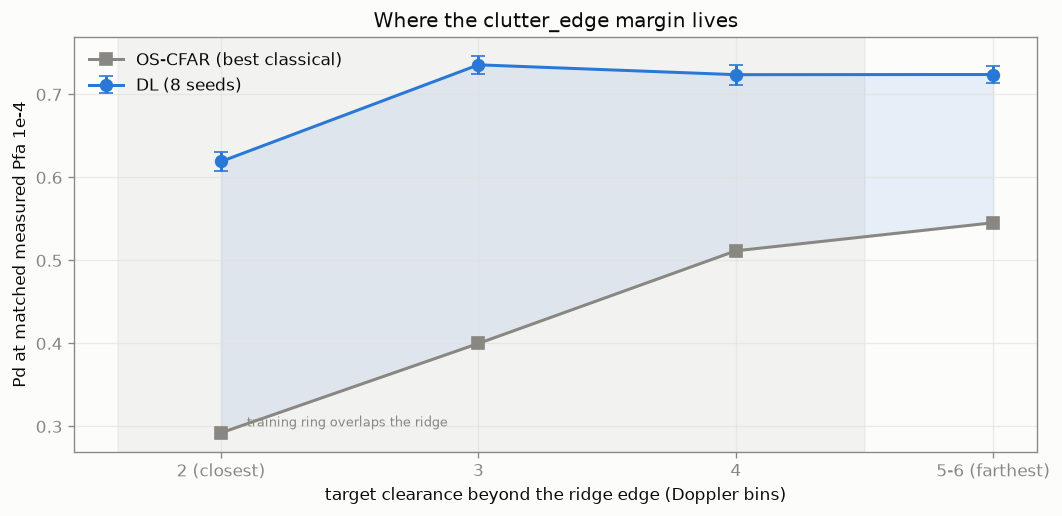

DL - best CFAR:  closest +0.327   farthest +0.114   difference +0.213
OS degrades +0.253 as the target approaches the ridge; DL degrades +0.105


In [10]:
att = DL / "clutter_edge_attribution.csv"
if att.exists():
    a = pd.read_csv(att)
    order = ["2 (closest)", "3", "4", "5-6 (farthest)"]
    dl = a[a.method == "DL"].groupby("band").pd.agg(["mean", "std", "count"]).reindex(order)
    dl["se"] = dl["std"] / np.sqrt(dl["count"])
    cf = a[a.method != "DL"].pivot_table(index="band", columns="method", values="pd").reindex(order)

    t = pd.DataFrame({"n frames": a[a.method == "CA"].set_index("band").n.reindex(order),
                      "true edge": [True, True, True, False],
                      "CA": cf.CA, "GO": cf.GO, "OS": cf.OS,
                      "best CFAR": cf.max(axis=1), "DL": dl["mean"], "DL SE": dl["se"]})
    t["DL - OS"] = t.DL - t.OS
    t["DL - best"] = t.DL - t["best CFAR"]
    display(t.round(3))

    fig, ax = plt.subplots(figsize=(9, 4.4))
    x = np.arange(len(order))
    ax.plot(x, t.OS, "s-", color=CFARC, lw=1.8, ms=7, label="OS-CFAR (best classical)")
    ax.errorbar(x, t.DL, yerr=1.96 * t["DL SE"], fmt="o-", color=DLC, lw=1.8, ms=7,
                capsize=4, label="DL (8 seeds)")
    ax.fill_between(x, t.OS, t.DL, color=DLC, alpha=0.10)
    ax.axvspan(-0.4, 2.5, color=MUTED, alpha=0.08)
    ax.text(0.1, 0.30, "training ring overlaps the ridge", fontsize=8, color=MUTED)
    ax.set_xticks(x); ax.set_xticklabels(order)
    ax.set_xlabel("target clearance beyond the ridge edge (Doppler bins)")
    ax.set_ylabel("Pd at matched measured Pfa 1e-4")
    ax.set_title("Where the clutter_edge margin lives")
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

    print(f"DL - best CFAR:  closest {t['DL - best'].iloc[0]:+.3f}   farthest "
          f"{t['DL - best'].iloc[-1]:+.3f}   difference {t['DL - best'].iloc[0]-t['DL - best'].iloc[-1]:+.3f}")
    print(f"OS degrades {t.OS.iloc[-1]-t.OS.iloc[0]:+.3f} as the target approaches the ridge; "
          f"DL degrades {t.DL.iloc[-1]-t.DL.iloc[0]:+.3f}")
else:
    print("run: python scripts/attribute_clutter_edge.py")

**What it showed — H-window, supported.**

CFAR falls apart as the target approaches the ridge: OS goes 0.545 → 0.512 → 0.400 → **0.292**, a
drop of 0.253. DL is nearly flat over the same span: 0.724 → 0.724 → 0.736 → 0.619, a drop of 0.105,
and only in the closest band. That asymmetry *is* the reference-window signature — CFAR is
handicapped exactly where its training ring overlaps the ridge, and the network, having no reference
window, is not.

The margin follows: **+0.327 / +0.336 / +0.212** on the three true-edge bands against **+0.114** on
the non-edge band. That +0.114 is the same order as DL's general advantage elsewhere (isolated
+0.022, multi +0.031, masking +0.049, mixed +0.086) — so on frames that are not really edges, the
network wins by roughly its usual amount, and on genuine edges by two to three times that.

**Dilution cannot be the explanation — it works the other way.** The 28% non-edge frames carry the
*smallest* margin, so they drag the pooled figure **down**. The pooled +0.261 therefore
*understates* the true-edge effect, which is nearer +0.28 when frame-weighted.

**Strength of evidence, honestly.** The near-vs-far contrast is ~2.7σ allowing for CFAR's own
sampling error (~0.055 per band at 40–57 frames), supported by a near-monotone gradient across four
bands. Not overwhelming on the endpoint contrast alone; the gradient and the mechanism agreeing is
what makes it convincing. The two middle bands invert slightly (+0.327 vs +0.336), which is well
within that error.

**Reportable**, with the mechanism stated and the caveat that per-band counts are 40–57 frames.

### O2 — `unresolved` +0.002 is not a win
p = 0.048, but both methods sit at the ~0.5 physics cap (two targets inside one mainlobe; one
detection can match only one truth). The significance is an artefact of a very small SE (0.0008),
not a detection advantage. **Do not report as a win.**

### O3 — `pos_weight` ablation pending
{100, 200, 974}, and it **must be seed-averaged** — single-seed it would have to clear a noise floor
of the same order as the effect. `pos_weight=974` is currently a principled default (the measured
inverse frequency), not a measured optimum.

---
## Next experiments

Running to-do in the same per-experiment format, results blank. Fill in and move up into the
chronological list once run.

### N1 — `pos_weight` ablation
- **Question:** is 974 (exact class balancing) better than 200 or 100 on Pd at matched measured Pfa?
- **Setup:** 3–5 seeds × 50 epochs per value; `bench2_val`; everything else unchanged.
  `python scripts/train_tinycnn.py --epochs 50 --seed $S --pos-weight $W --tag pw${W}_s$S ...`
- **Results:** *(pending)*
- **What it showed:** *(pending)*
- **What it changed:** *(pending)*

### N2 — `clutter_edge` attribution: true-edge vs diluted frames
- **Question:** does the +0.261 margin hold on frames where the window genuinely straddles the ridge,
  or does it come from the 34% that do not?
- **Setup:** re-run the Milestone-22 split on the 8 DL checkpoints; compare against the CFAR
  true-edge numbers already measured.
- **Results / showed / changed:** *(pending)*

### N3 — why DL loses on `clutter`
- **Question:** what does CFAR's local statistic capture inside the ridge that the network does not?
- **Setup:** per-frame comparison at matched Pfa on `clutter`; inspect frames where CFAR detects and
  DL misses; check whether the deficit concentrates at particular CNR or Weibull shape (both swept
  and recorded per frame).
- **Results / showed / changed:** *(pending)*

### N4 — final test-split evaluation
- **Question:** the reportable numbers.
- **Setup:** **only once the configuration is locked.** Seed-averaged DL vs CFAR on `bench2_test`,
  same protocol. Until then `bench2_test` stays untouched.
- **Results / showed / changed:** *(pending)*